# AdvisoryLens: An ETL & EDA Pipeline for Open-Source Security Advisories

**Authors:** Ammara Naveed, Sadia Shafiq, Afia Sajal

## 1. Project Introduction

Open-source packages (npm, pip, Go modules, Maven, ...) are used by almost every modern application, so a
vulnerability in one popular package can affect thousands of projects. GitHub publishes **reviewed security
advisories** for these packages through its *Global Security Advisories* API.

**AdvisoryLens** collects these advisories and prepares them for analysis with a four-stage ETL pipeline:

| Stage | Tool | What it does |
|---|---|---|
| Extract | `requests` | Downloads the 1,500 most recently published reviewed advisories from the GitHub API |
| Transform | `pandas` | Flattens the JSON, keeps v3/v4 CVSS scores, handles missing values, removes duplicates |
| Validate | `Pydantic` | Checks every record against a strict schema before it is loaded |
| Load | `SQLite` | Stores the validated records in `database/advisories.db` |

This notebook is the **Exploratory Data Analysis (EDA)** stage. It reads the loaded data from the SQLite
database and analyses severity, ecosystems, CVSS scores, weakness types (CWE), publication timing and
affected packages.

**Scope of the data:** the API returns advisories newest-first, so the dataset is the *latest 1,500 reviewed
advisories* (published 18 Sep 2026 to 30 Oct 2026, about six weeks). It is **not** a multi-year sample, so
this notebook does not make long-term trend claims.

## 2. Objectives

The EDA answers these research questions:

1. **Data quality:** how complete and reliable is the dataset?
2. **Severity:** how are advisories distributed across severity levels?
3. **Ecosystems:** which ecosystems appear most often, and does severity differ between them?
4. **CVSS:** how are CVSS scores distributed, and how do they relate to the severity label?
5. **CWE:** which weakness types occur most often (counting every CWE of multi-CWE advisories)?
6. **Time:** when are advisories published (daily and weekly pattern)?
7. **Packages:** which individual packages are affected most often?

### Setup: libraries, paths and data loading

The next cell finds the project root automatically, so the notebook works whether Jupyter is started from the
project root or from the `notebooks/` folder. All charts are saved to `outputs/visualizations/`.

In [46]:
from contextlib import closing
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import Markdown, display

# ---------- One shared style so every chart looks consistent ----------
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 100,
})

SEVERITY_ORDER = ["critical", "high", "medium", "low"]
SEVERITY_COLORS = {"critical": "#b30000", "high": "#e65c00", "medium": "#d4ac0d", "low": "#0066cc"}
PRIMARY_COLOR = "#1f4e79"


# ---------- Project paths (work from the project root or from notebooks/) ----------
def find_project_root():
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "pipeline.py").exists():
            return folder
    raise FileNotFoundError("Project root not found. Open the notebook inside the AdvisoryLens folder.")


ROOT = find_project_root()
DB_PATH = ROOT / "database" / "advisories.db"
CSV_PATH = ROOT / "data" / "processed" / "processed_advisories.csv"
VIZ_DIR = ROOT / "outputs" / "visualizations"
VIZ_DIR.mkdir(parents=True, exist_ok=True)


# ---------- Small helper functions used by many sections ----------
def save_figure(fig, filename):
    """Save a chart to outputs/visualizations/ in high resolution."""
    fig.savefig(VIZ_DIR / filename, dpi=300, bbox_inches="tight")
    print(f"Saved: outputs/visualizations/{filename}")


def show(*lines):
    """Display lines of Markdown text (used for the data-driven observations)."""
    display(Markdown("\n".join(lines)))


def explode_multi(frame, column):
    """
    Turn a column such as "npm, pip" into one row per value.
    Used so multi-value fields (ecosystem, package, CWE) are counted correctly.
    """
    out = frame.dropna(subset=[column]).copy()
    out[column] = out[column].str.split(", ")
    out = out.explode(column)
    out[column] = out[column].str.strip()
    return out.reset_index(drop=True)


# ---------- Load the data: SQLite database first, processed CSV as fallback ----------
if DB_PATH.exists():
    with closing(sqlite3.connect(DB_PATH)) as conn:
        df = pd.read_sql_query("SELECT * FROM advisories", conn)
    DATA_SOURCE = "SQLite database  (database/advisories.db)"
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    DATA_SOURCE = "processed CSV  (data/processed/processed_advisories.csv)"
else:
    raise FileNotFoundError("No data found. From the project root run:  python pipeline.py --skip-extract")

# ---------- Correct data types ----------
df["published_at"] = pd.to_datetime(df["published_at"], utc=True)
df["updated_at"] = pd.to_datetime(df["updated_at"], utc=True)
df["is_withdrawn"] = df["is_withdrawn"].astype(bool)

print(f"Data source      : {DATA_SOURCE}")
print(f"Records loaded   : {len(df):,}")
print(f"Project root     : {ROOT}")

# ---------- Cross-check: database and CSV must contain the same advisories ----------
if CSV_PATH.exists() and DB_PATH.exists():
    csv_ids = set(pd.read_csv(CSV_PATH, usecols=["ghsa_id"])["ghsa_id"])
    same = csv_ids == set(df["ghsa_id"])
    print(f"DB and CSV hold the same advisories: {same}")

Data source      : SQLite database  (database/advisories.db)
Records loaded   : 1,500
Project root     : C:\Users\User\Desktop\AdvisoryLens
DB and CSV hold the same advisories: True


## 3. Dataset Overview

**Research question:** what does the dataset contain (size, columns, data types, value ranges)?

**What is measured:** record and column counts, data types, numeric summary statistics and the date range.

In [24]:
print(f"Records : {len(df):,}")
print(f"Columns : {df.shape[1]}")
print(f"Published from {df['published_at'].min():%d %b %Y} to {df['published_at'].max():%d %b %Y} (UTC)\n")

print("--- Data types and non-null counts ---")
df.info()

Records : 1,500
Columns : 14
Published from 18 Sep 2026 to 30 Oct 2026 (UTC)

--- Data types and non-null counts ---
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype              
---  ------         --------------  -----              
 0   ghsa_id        1500 non-null   str                
 1   cve_id         1312 non-null   str                
 2   summary        1500 non-null   str                
 3   severity       1500 non-null   str                
 4   cvss_score     1486 non-null   float64            
 5   cvss_version   1486 non-null   str                
 6   cvss_v3_score  1073 non-null   float64            
 7   cvss_v4_score  478 non-null    float64            
 8   published_at   1500 non-null   datetime64[us, UTC]
 9   updated_at     1500 non-null   datetime64[us, UTC]
 10  is_withdrawn   1500 non-null   bool               
 11  cwe_ids        1494 non-null   str                
 12

In [25]:
print("--- Numeric summary (CVSS columns; missing scores are excluded, not counted as 0) ---")
display(df[["cvss_score", "cvss_v3_score", "cvss_v4_score"]].describe().round(2))

print("\n--- Number of distinct values per column (a cell with several values, e.g. \"npm, pip\", counts as one value here) ---")
distinct = df[["ghsa_id", "severity", "ecosystem", "package_name", "cwe_ids", "cvss_version"]].nunique()
display(distinct.rename("distinct_values").to_frame())

print("\n--- First 3 records ---")
display(df.head(3))

--- Numeric summary (CVSS columns; missing scores are excluded, not counted as 0) ---


,cvss_score,cvss_v3_score,cvss_v4_score
count,1486.00,1073.00,478.00
mean,6.83,6.71,7.10
std,1.77,1.70,1.89
min,0.00,0.00,1.00
25%,5.80,5.40,6.30
50%,7.10,6.80,7.10
75%,8.20,7.60,8.70
max,10.00,10.00,10.00



--- Number of distinct values per column (a cell with several values, e.g. "npm, pip", counts as one value here) ---


,distinct_values
ghsa_id,1500
severity,4
ecosystem,18
package_name,571
cwe_ids,522
cvss_version,2



--- First 3 records ---


,ghsa_id,cve_id,summary,severity,cvss_score,cvss_version,cvss_v3_score,cvss_v4_score,published_at,updated_at,is_withdrawn,cwe_ids,ecosystem,package_name
0,GHSA-jm85-8cpp-9cjc,CVE-2026-59978,AdminNeo: version-cache array injection causes...,high,7.5,3.x,7.5,NaN,2026-10-30 18:53:08+00:00,2026-10-30 18:53:08+00:00,False,CWE-20,composer,adminneo-org/adminneo
1,GHSA-9pg5-8c7x-5hfx,CVE-2026-119284,joserfc: Compact JWS size guard allocates atta...,medium,6.9,4.0,NaN,6.9,2026-10-30 14:54:25+00:00,2026-10-30 14:54:26+00:00,False,CWE-400,pip,joserfc
2,GHSA-jpxq-7h8p-2q76,CVE-2026-119283,joserfc: Unbounded JWE General JSON `recipient...,high,7.5,3.x,7.5,NaN,2026-10-30 14:54:20+00:00,2026-10-30 14:54:20+00:00,False,CWE-400,pip,joserfc


**Column guide:** `ghsa_id` (unique advisory id), `cve_id` (CVE id, if one exists), `summary`, `severity`
(GitHub label: low / medium / high / critical), `cvss_score` (preferred score: CVSS v4 if available, otherwise
v3), `cvss_version`, `cvss_v3_score`, `cvss_v4_score`, `published_at`, `updated_at`, `is_withdrawn`,
`cwe_ids` (one or more weakness ids), `ecosystem` and `package_name` (one or more, comma separated).

**Note:** `ecosystem`, `package_name` and `cwe_ids` can hold several values in one cell. They are split
(exploded) before counting in the sections below, so every value is counted correctly.

## 4. Data Quality Assessment

**Research question:** how complete and trustworthy is the dataset, and which gaps can affect the analysis?

**What is measured:** missing values per column, duplicate records, CVSS score availability and withdrawn
advisories.

In [26]:
# ---------- Missing values ----------
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
})
meaning = {
    "cve_id": "No CVE id was assigned (GitHub-only advisory)",
    "cwe_ids": "No weakness type (CWE) was assigned",
    "cvss_score": "No CVSS v3 or v4 score published",
    "cvss_version": "Same advisories as cvss_score",
    "cvss_v3_score": "Scored with v4 only, or not scored",
    "cvss_v4_score": "Older advisories scored with v3 only, or not scored",
}
missing["meaning"] = pd.Series(meaning)
print("--- Columns with missing values ---")
display(missing[missing["missing_count"] > 0])

# ---------- Duplicates ----------
dup_ids = int(df["ghsa_id"].duplicated().sum())
dup_rows = int(df.duplicated().sum())
print(f"\nDuplicate ghsa_id values : {dup_ids}")
print(f"Fully duplicated rows    : {dup_rows}")

# ---------- Which CVSS version scored each advisory? ----------
has_v3 = df["cvss_v3_score"].notna()
has_v4 = df["cvss_v4_score"].notna()
cvss_source = pd.Series(
    np.select([has_v3 & has_v4, has_v3, has_v4], ["v3 and v4", "v3 only", "v4 only"], default="no score"),
    index=df.index,
)
cvss_source_counts = cvss_source.value_counts().reindex(["v3 only", "v4 only", "v3 and v4", "no score"], fill_value=0)
print("\n--- CVSS availability ---")
display(cvss_source_counts.rename("advisories").to_frame())

n_withdrawn = int(df["is_withdrawn"].sum())
print(f"\nWithdrawn advisories (kept, flagged with is_withdrawn): {n_withdrawn}")

--- Columns with missing values ---


,missing_count,missing_pct,meaning
cve_id,188,12.5,No CVE id was assigned (GitHub-only advisory)
cvss_score,14,0.9,No CVSS v3 or v4 score published
cvss_version,14,0.9,Same advisories as cvss_score
cvss_v3_score,427,28.5,"Scored with v4 only, or not scored"
cvss_v4_score,1022,68.1,"Older advisories scored with v3 only, or not s..."
cwe_ids,6,0.4,No weakness type (CWE) was assigned



Duplicate ghsa_id values : 0
Fully duplicated rows    : 0

--- CVSS availability ---


,advisories
v3 only,1008
v4 only,413
v3 and v4,65
no score,14



Withdrawn advisories (kept, flagged with is_withdrawn): 26


Saved: outputs/visualizations/data_quality.png


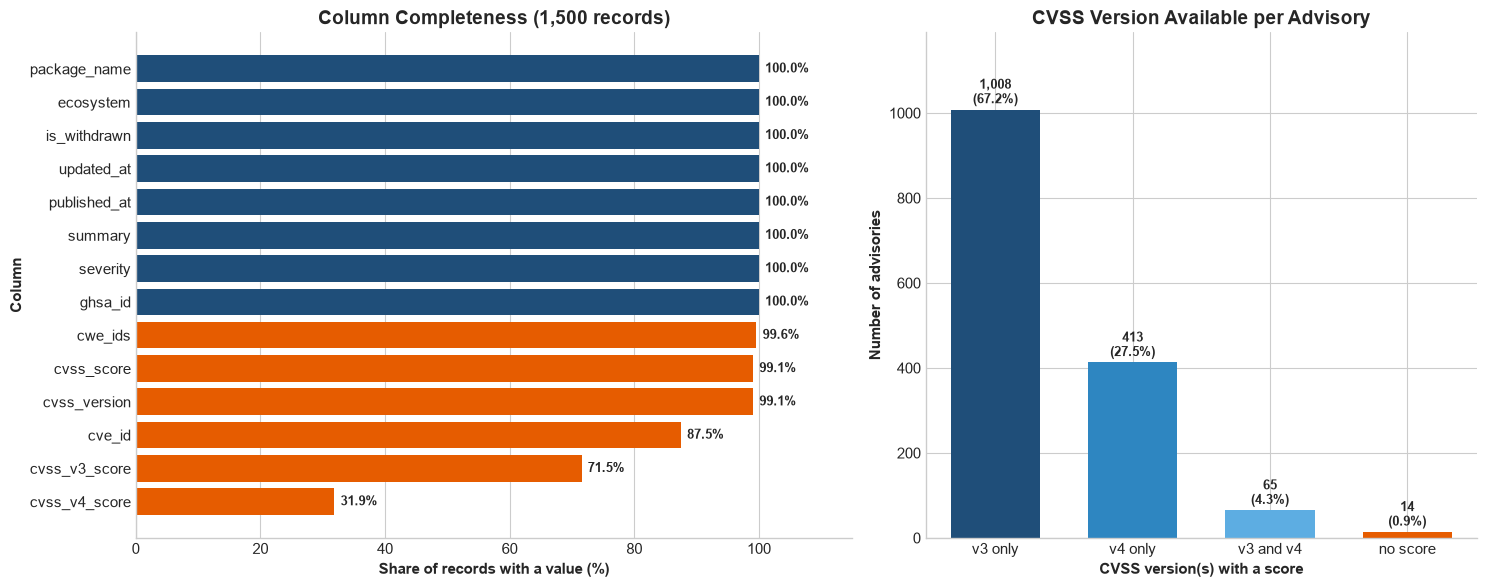

In [27]:
completeness = (df.notna().mean() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})

# Left: completeness of every column
ax = axes[0]
colors = ["#e65c00" if v < 100 else PRIMARY_COLOR for v in completeness]
ax.barh(completeness.index, completeness.values, color=colors)
ax.set_xlim(0, 115)
ax.grid(axis="y", visible=False)
for y, v in enumerate(completeness.values):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=9, fontweight="bold")
ax.set_title(f"Column Completeness ({len(df):,} records)")
ax.set_xlabel("Share of records with a value (%)")
ax.set_ylabel("Column")

# Right: which CVSS version is available
ax = axes[1]
bar_colors = [PRIMARY_COLOR, "#2e86c1", "#5dade2", "#e65c00"]
ax.bar(cvss_source_counts.index, cvss_source_counts.values, color=bar_colors, width=0.65)
for x, v in enumerate(cvss_source_counts.values):
    ax.text(x, v + len(df) * 0.01, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, cvss_source_counts.max() * 1.18)
ax.set_title("CVSS Version Available per Advisory")
ax.set_xlabel("CVSS version(s) with a score")
ax.set_ylabel("Number of advisories")

plt.tight_layout()
save_figure(fig, "data_quality.png")
plt.show()

In [29]:
n_no_cvss = int(df["cvss_score"].isna().sum())
n_no_cve = int(df["cve_id"].isna().sum())
n_no_cwe = int(df["cwe_ids"].isna().sum())

show(
    "**Key observations**",
    f"- The dataset has **no duplicate advisories** ({dup_ids} duplicate ids, {dup_rows} duplicate rows) and every record passed schema validation.",
    f"- Only **{n_no_cvss}** advisories ({n_no_cvss / len(df) * 100:.1f}%) have no CVSS score at all; "
    f"**{int(has_v4.sum())}** ({has_v4.mean() * 100:.1f}%) have a CVSS v4 score and **{int(has_v3.sum())}** ({has_v3.mean() * 100:.1f}%) have a v3 score.",
    f"- **{n_no_cve}** advisories ({n_no_cve / len(df) * 100:.1f}%) have no CVE id and **{n_no_cwe}** ({n_no_cwe / len(df) * 100:.1f}%) have no CWE.",
    f"- **{n_withdrawn}** advisories ({n_withdrawn / len(df) * 100:.1f}%) have been withdrawn by GitHub but are still in the dataset (flagged by `is_withdrawn`).",
)

**Key observations**
- The dataset has **no duplicate advisories** (0 duplicate ids, 0 duplicate rows) and every record passed schema validation.
- Only **14** advisories (0.9%) have no CVSS score at all; **478** (31.9%) have a CVSS v4 score and **1073** (71.5%) have a v3 score.
- **188** advisories (12.5%) have no CVE id and **6** (0.4%) have no CWE.
- **26** advisories (1.7%) have been withdrawn by GitHub but are still in the dataset (flagged by `is_withdrawn`).

**Interpretation:** the dataset is highly complete. The few missing values are *meaningful gaps*, not errors:
a GitHub advisory does not need a CVE id, and not every advisory has been classified with a CWE or scored.
Missing CVSS scores are stored as missing (NULL) and are **never replaced by 0**, because a zero would be
read as "no risk". This matters: in the first version of this project, filling missing scores with 0.0
turned about 29% of the records into false zeros and pulled the mean CVSS score down from about 6.8 to 4.8.

**Limitations:**
- CVSS v3 and v4 are different scoring systems; 478 advisories are scored with v4 and 1,008 with v3 only.
- Withdrawn advisories (1.7%) are kept to preserve the 1,500-record sample; they are too few to change
  the overall patterns.
- The dataset contains only GitHub-*reviewed* advisories, so it does not represent all vulnerabilities.

## 5. Severity Analysis

**Research question:** how are advisories distributed across the four severity levels?

**What is measured:** the number and percentage of advisories per severity label assigned by GitHub.

Severity breakdown:
- Critical :  128 (8.5%)
- High     :  643 (42.9%)
- Medium   :  621 (41.4%)
- Low      :  108 (7.2%)
Saved: outputs/visualizations/severity_distribution.png


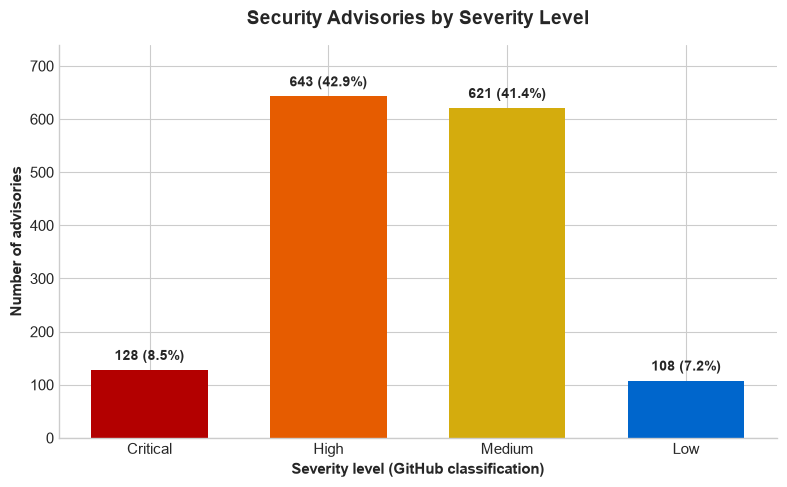

In [30]:
sev_counts = df["severity"].value_counts().reindex(SEVERITY_ORDER).fillna(0).astype(int)
sev_pct = sev_counts / len(df) * 100

print("Severity breakdown:")
for sev in SEVERITY_ORDER:
    print(f"- {sev.capitalize():<9}: {sev_counts[sev]:>4} ({sev_pct[sev]:.1f}%)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    [s.capitalize() for s in SEVERITY_ORDER],
    sev_counts.values,
    color=[SEVERITY_COLORS[s] for s in SEVERITY_ORDER],
    width=0.65,
)
for x, sev in enumerate(SEVERITY_ORDER):
    ax.annotate(
        f"{sev_counts[sev]:,} ({sev_pct[sev]:.1f}%)",
        (x, sev_counts[sev]), ha="center", va="bottom",
        fontsize=10, fontweight="bold", xytext=(0, 5), textcoords="offset points",
    )
ax.set_ylim(0, sev_counts.max() * 1.15)
ax.set_title("Security Advisories by Severity Level", pad=15)
ax.set_xlabel("Severity level (GitHub classification)")
ax.set_ylabel("Number of advisories")
plt.tight_layout()
save_figure(fig, "severity_distribution.png")
plt.show()

In [31]:
total = len(df)
top_sev = sev_counts.idxmax()
high_medium = int(sev_counts[["high", "medium"]].sum())
critical_high = int(sev_counts[["critical", "high"]].sum())

show(
    "**Key observations**",
    f"- **{top_sev.capitalize()}** is the most common level: {sev_counts[top_sev]:,} advisories ({sev_pct[top_sev]:.1f}%).",
    f"- High and medium together account for **{high_medium / total * 100:.1f}%** of all advisories.",
    f"- Critical and high together make up **{critical_high:,}** advisories ({critical_high / total * 100:.1f}%), the group that normally needs urgent patching.",
    f"- Critical ({sev_pct['critical']:.1f}%) and low ({sev_pct['low']:.1f}%) are the two smallest groups.",
)

**Key observations**
- **High** is the most common level: 643 advisories (42.9%).
- High and medium together account for **84.3%** of all advisories.
- Critical and high together make up **771** advisories (51.4%), the group that normally needs urgent patching.
- Critical (8.5%) and low (7.2%) are the two smallest groups.

**Interpretation:** the distribution is concentrated in the two middle levels. Most reported weaknesses are
serious but not catastrophic, which is typical for a severity scale. Critical advisories are a minority, but
128 critical advisories in about six weeks is still a large absolute number for maintainers to handle.

**Limitations:** severity is GitHub's label (which follows the CVSS score, see Section 7). It does not measure
how likely a vulnerability is to be exploited or how many users are affected, and the counts describe
*advisories*, not individual vulnerabilities in the wild.

## 6. Ecosystem Analysis

**Research questions:** which software ecosystems (package managers) have the most advisories, and does the
severity mix differ between them?

**What is measured:** the number of advisories per ecosystem, and the percentage of each severity level
inside the larger ecosystems.

**Counting rule:** some advisories affect several ecosystems (for example `npm, pip`). They are split and
counted **once under each ecosystem**, so the counts add up to more than the number of advisories.

Distinct ecosystems: 11
Advisories affecting more than one ecosystem: 11

Advisories per ecosystem:


,advisories
ecosystem,
npm,572
pip,454
go,244
composer,61
nuget,61
maven,60
rust,44
rubygems,14
erlang,6


Saved: outputs/visualizations/ecosystem_analysis.png


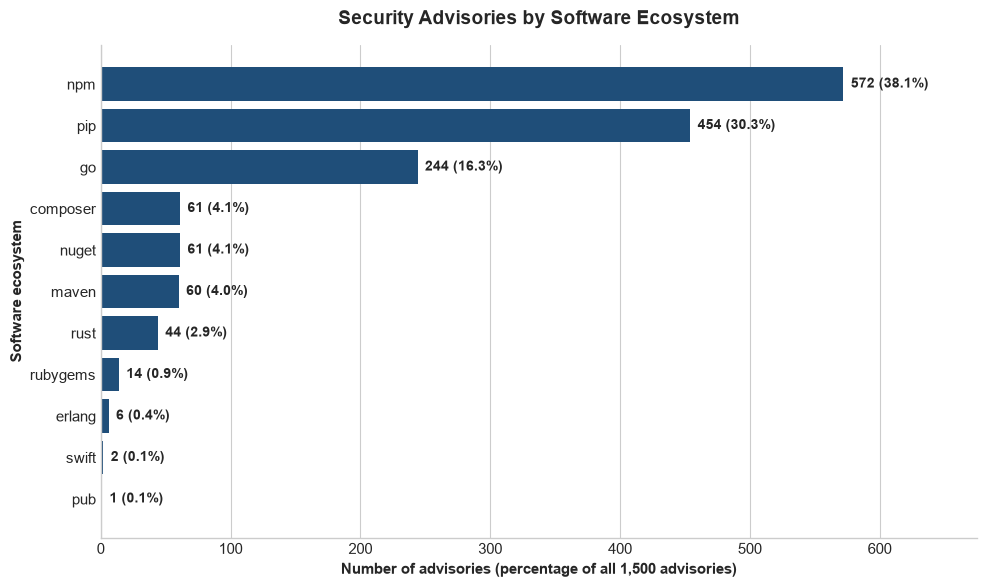

In [32]:
eco = explode_multi(df, "ecosystem")                 # one row per (advisory, ecosystem)
eco_counts = eco["ecosystem"].value_counts()
n_multi_eco = int(df["ecosystem"].str.contains(",").sum())

print(f"Distinct ecosystems: {eco_counts.size}")
print(f"Advisories affecting more than one ecosystem: {n_multi_eco}\n")
print("Advisories per ecosystem:")
display(eco_counts.rename("advisories").to_frame())

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(eco_counts.index, eco_counts.values, color=PRIMARY_COLOR)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)                                     # largest ecosystem on top
for y, v in enumerate(eco_counts.values):
    ax.text(v + eco_counts.max() * 0.01, y, f"{v:,} ({v / len(df) * 100:.1f}%)", va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0, eco_counts.max() * 1.18)
ax.set_title("Security Advisories by Software Ecosystem", pad=15)
ax.set_xlabel(f"Number of advisories (percentage of all {len(df):,} advisories)")
ax.set_ylabel("Software ecosystem")
plt.tight_layout()
save_figure(fig, "ecosystem_analysis.png")
plt.show()

Severity counts for ecosystems with at least 40 advisories:


severity,critical,high,medium,low
ecosystem,,,,
npm,60,236,220,56
pip,38,190,202,24
go,15,107,111,11
composer,3,27,26,5
nuget,4,41,15,1
maven,5,26,27,2
rust,3,12,18,11


Saved: outputs/visualizations/ecosystem_severity.png


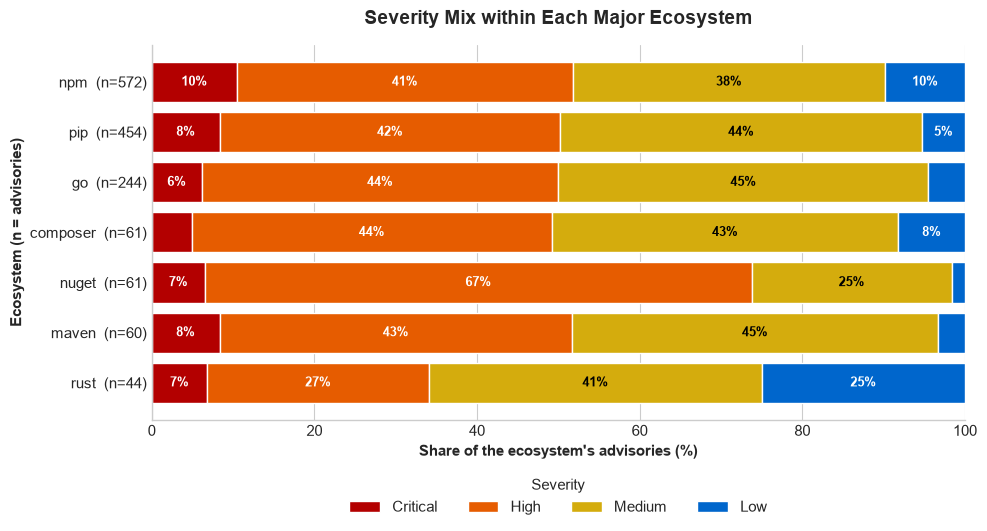

In [33]:
# Severity mix inside the larger ecosystems only (small groups give unreliable percentages)
MIN_ECOSYSTEM_SIZE = 40
big_ecosystems = eco_counts[eco_counts >= MIN_ECOSYSTEM_SIZE].index

ct = (
    pd.crosstab(eco["ecosystem"], eco["severity"])
    .reindex(index=big_ecosystems, columns=SEVERITY_ORDER, fill_value=0)
)
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

print(f"Severity counts for ecosystems with at least {MIN_ECOSYSTEM_SIZE} advisories:")
display(ct)

fig, ax = plt.subplots(figsize=(10, 5.5))
left = np.zeros(len(ct_pct))
for sev in SEVERITY_ORDER:
    values = ct_pct[sev].values
    ax.barh(range(len(ct_pct)), values, left=left, color=SEVERITY_COLORS[sev],
            edgecolor="white", label=sev.capitalize())
    for i, (start, width) in enumerate(zip(left, values)):
        if width >= 5:
            ax.text(start + width / 2, i, f"{width:.0f}%", ha="center", va="center", fontsize=9,
                    fontweight="bold", color="black" if sev == "medium" else "white")
    left += values
ax.set_yticks(range(len(ct_pct)))
ax.set_yticklabels([f"{e}  (n={int(ct.loc[e].sum())})" for e in ct_pct.index])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 100)
ax.set_title("Severity Mix within Each Major Ecosystem", pad=15)
ax.set_xlabel("Share of the ecosystem's advisories (%)")
ax.set_ylabel("Ecosystem (n = advisories)")
ax.legend(title="Severity", ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout()
save_figure(fig, "ecosystem_severity.png")
plt.show()

In [34]:
top3 = list(eco_counts.index[:3])
top3_adv = eco.loc[eco["ecosystem"].isin(top3), "ghsa_id"].nunique()
crit_leader = ct_pct["critical"].idxmax()
low_leader = ct_pct["low"].idxmax()
high_leader = ct_pct["high"].idxmax()

show(
    "**Key observations**",
    f"- **{top3[0]}** ({eco_counts[top3[0]]:,}), **{top3[1]}** ({eco_counts[top3[1]]:,}) and **{top3[2]}** ({eco_counts[top3[2]]:,}) are the three largest ecosystems; "
    f"together they cover **{top3_adv / len(df) * 100:.1f}%** of all advisories.",
    f"- Only **{n_multi_eco}** advisories ({n_multi_eco / len(df) * 100:.1f}%) affect more than one ecosystem.",
    f"- Among the {len(big_ecosystems)} ecosystems with at least {MIN_ECOSYSTEM_SIZE} advisories, **{crit_leader}** has the highest critical share ({ct_pct.loc[crit_leader, 'critical']:.1f}%, n={int(ct.loc[crit_leader].sum())}), "
    f"**{high_leader}** the highest high share ({ct_pct.loc[high_leader, 'high']:.1f}%) and **{low_leader}** the highest low share ({ct_pct.loc[low_leader, 'low']:.1f}%).",
)

**Key observations**
- **npm** (572), **pip** (454) and **go** (244) are the three largest ecosystems; together they cover **84.4%** of all advisories.
- Only **11** advisories (0.7%) affect more than one ecosystem.
- Among the 7 ecosystems with at least 40 advisories, **npm** has the highest critical share (10.5%, n=572), **nuget** the highest high share (67.2%) and **rust** the highest low share (25.0%).

**Interpretation:** three ecosystems (npm, pip and Go) dominate the dataset. This mostly reflects how large
and how actively audited these ecosystems are, not necessarily that they are *less secure* than the others:
an ecosystem with more packages and more researchers will naturally receive more advisories. In the three largest ecosystems
the severity mix is similar (high and medium dominate in each). The larger deviations appear only in the small
ecosystems (for example nuget has an unusually high share of high advisories and rust a high share of low ones), where
the group sizes are small and a few advisories change the percentages a lot.

**Limitations:**
- Raw counts are not normalised by the number of packages or downloads in each ecosystem (this information is
  not in the dataset), so the chart cannot rank ecosystems by *security quality*.
- Ecosystems with few advisories (for example nuget with 61, rust with 44) have unstable percentages: one or two
  advisories change the shares noticeably. Differences are described, not statistically tested.
- Ecosystems with fewer than 40 advisories are shown in the first chart but left out of the severity comparison.

## 7. CVSS Analysis

**Research questions:** how are CVSS scores distributed, and how do they relate to the severity label?

**What is measured:** the distribution of `cvss_score` (CVSS v4 when available, otherwise v3) for the
advisories that have a score, summary statistics, and the score range inside each severity level.

**Important:** advisories without any score are **excluded** here (they are missing, not zero).

Advisories with a CVSS score: 1,486 of 1,500



,cvss_score
count,1486.00
mean,6.83
median,7.10
std,1.77
min,0.00
max,10.00


Saved: outputs/visualizations/cvss_distribution.png


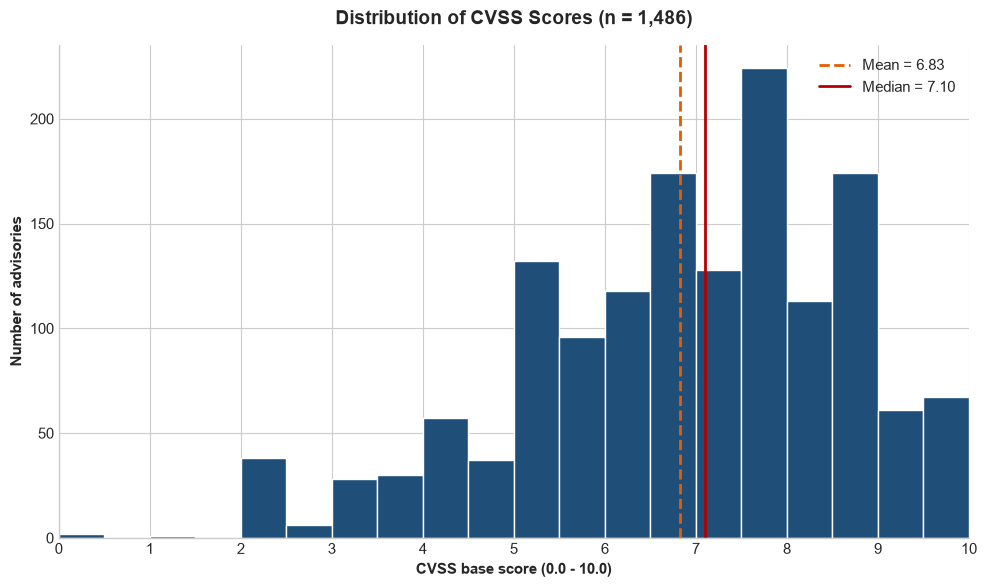

In [35]:
scored = df.dropna(subset=["cvss_score"])
n_scored = len(scored)
mean_cvss = scored["cvss_score"].mean()
median_cvss = scored["cvss_score"].median()

print(f"Advisories with a CVSS score: {n_scored:,} of {len(df):,}\n")
display(scored["cvss_score"].agg(["count", "mean", "median", "std", "min", "max"]).round(2).rename("cvss_score").to_frame())

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(scored["cvss_score"], bins=np.arange(0, 10.5, 0.5), color=PRIMARY_COLOR, edgecolor="white")
ax.axvline(mean_cvss, color="#e65c00", linestyle="--", linewidth=2, label=f"Mean = {mean_cvss:.2f}")
ax.axvline(median_cvss, color="#b30000", linestyle="-", linewidth=2, label=f"Median = {median_cvss:.2f}")
ax.set_title(f"Distribution of CVSS Scores (n = {n_scored:,})", pad=15)
ax.set_xlabel("CVSS base score (0.0 - 10.0)")
ax.set_ylabel("Number of advisories")
ax.set_xlim(0, 10)
ax.set_xticks(range(0, 11))
ax.legend(frameon=False)
plt.tight_layout()
save_figure(fig, "cvss_distribution.png")
plt.show()

CVSS score by severity level:


,count,min,median,mean,max
severity,,,,,
critical,128,9.0,9.5,9.54,10.0
high,639,7.0,7.7,7.91,8.9
medium,614,4.0,5.9,5.81,6.9
low,105,0.0,3.1,2.87,3.9


Saved: outputs/visualizations/cvss_by_severity.png


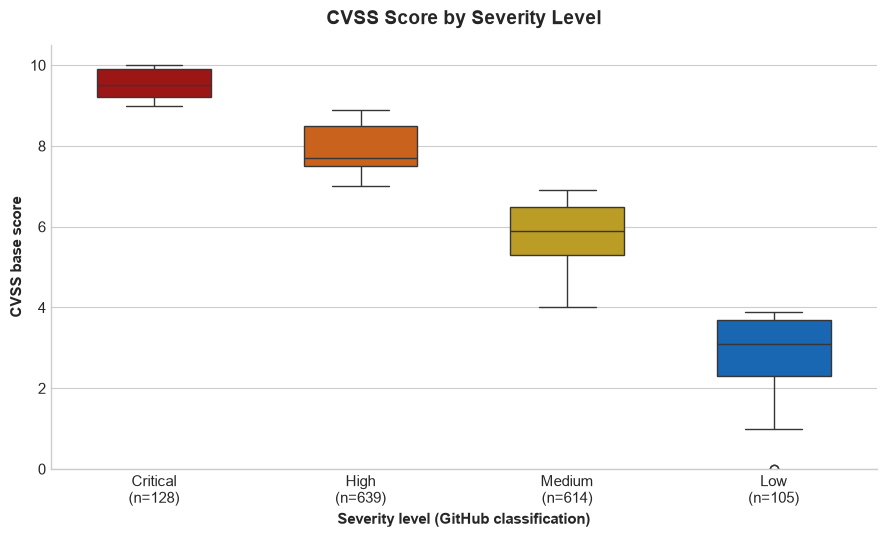


CVSS score by scoring version:


,count,mean,median
cvss_version,,,
3.x,1008,6.7,6.8
4.0,478,7.1,7.1


In [36]:
by_sev = (
    scored.groupby("severity")["cvss_score"]
    .agg(["count", "min", "median", "mean", "max"])
    .reindex(SEVERITY_ORDER)
    .round(2)
)
print("CVSS score by severity level:")
display(by_sev)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(
    data=scored, x="severity", y="cvss_score", order=SEVERITY_ORDER,
    hue="severity", palette=SEVERITY_COLORS, legend=False, width=0.55, ax=ax,
)
ax.set_xticks(range(len(SEVERITY_ORDER)))
ax.set_xticklabels([f"{s.capitalize()}\n(n={int(by_sev.loc[s, 'count'])})" for s in SEVERITY_ORDER])
ax.set_ylim(0, 10.5)
ax.set_title("CVSS Score by Severity Level", pad=15)
ax.set_xlabel("Severity level (GitHub classification)")
ax.set_ylabel("CVSS base score")
plt.tight_layout()
save_figure(fig, "cvss_by_severity.png")
plt.show()

print("\nCVSS score by scoring version:")
display(scored.groupby("cvss_version")["cvss_score"].agg(["count", "mean", "median"]).round(2))

In [37]:
low_to_high = ["low", "medium", "high", "critical"]
ranges = scored.groupby("severity")["cvss_score"].agg(["min", "max"]).reindex(low_to_high)
bands_do_not_overlap = all(
    ranges.loc[lower, "max"] < ranges.loc[upper, "min"]
    for lower, upper in zip(low_to_high[:-1], low_to_high[1:])
)
skew_text = "left-skewed (a tail of low scores pulls the mean below the median)" if median_cvss > mean_cvss else "right-skewed"
ver = scored.groupby("cvss_version")["cvss_score"].mean()
hist_counts, hist_edges = np.histogram(scored["cvss_score"], bins=np.arange(0, 10.5, 0.5))   # same bins as the chart
peak_i = int(hist_counts.argmax())
share_5_to_9 = scored["cvss_score"].between(5.0, 9.0).mean() * 100

show(
    "**Key observations**",
    f"- Scores cover the range **{scored['cvss_score'].min():.1f} - {scored['cvss_score'].max():.1f}** with mean **{mean_cvss:.2f}** and median **{median_cvss:.2f}**; the distribution is {skew_text}.",
    f"- **{share_5_to_9:.1f}%** of the scores lie between 5.0 and 9.0, and the tallest bar of the histogram is the {hist_edges[peak_i]:.1f}-{hist_edges[peak_i + 1]:.1f} range ({hist_counts[peak_i]} advisories).",
    f"- The four severity levels occupy **separate, non-overlapping score bands**: {bands_do_not_overlap}. "
    f"Critical: {ranges.loc['critical', 'min']:.1f}-{ranges.loc['critical', 'max']:.1f}, high: {ranges.loc['high', 'min']:.1f}-{ranges.loc['high', 'max']:.1f}, "
    f"medium: {ranges.loc['medium', 'min']:.1f}-{ranges.loc['medium', 'max']:.1f}, low: {ranges.loc['low', 'min']:.1f}-{ranges.loc['low', 'max']:.1f}.",
    f"- Advisories scored with CVSS 4.0 have a mean of {ver['4.0']:.2f}, those scored with 3.x have a mean of {ver['3.x']:.2f}.",
    f"- {int((scored['cvss_score'] == 0).sum())} advisories have a genuine score of 0.0 (a vector with no impact), labelled: {', '.join(sorted(scored.loc[scored['cvss_score'] == 0, 'severity'].unique()))}.",
)

**Key observations**
- Scores cover the range **0.0 - 10.0** with mean **6.83** and median **7.10**; the distribution is left-skewed (a tail of low scores pulls the mean below the median).
- **78.2%** of the scores lie between 5.0 and 9.0, and the tallest bar of the histogram is the 7.5-8.0 range (224 advisories).
- The four severity levels occupy **separate, non-overlapping score bands**: True. Critical: 9.0-10.0, high: 7.0-8.9, medium: 4.0-6.9, low: 0.0-3.9.
- Advisories scored with CVSS 4.0 have a mean of 7.10, those scored with 3.x have a mean of 6.70.
- 2 advisories have a genuine score of 0.0 (a vector with no impact), labelled: low.

**Interpretation:** most advisories are scored in the upper-middle range (see the share between 5.0 and 9.0 above), with the
tallest bars in the upper half of the scale and a short tail of low scores. The severity label is simply the CVSS score converted into a category, so the
two measures carry the same information: this is also why the boxplot shows no overlap between levels. The
CVSS score is therefore the more *detailed* measure, while the severity label is the easier one to communicate.

**Limitations:**
- Scores come from two CVSS versions. The version 4.0 group has a slightly higher mean, but these are
  *different advisories*, so this does not prove that v4 scores the same vulnerability higher.
- 14 advisories have no score and are not in the charts.
- CVSS measures technical severity, not real-world exploitation or business impact.

## 8. CWE Analysis

**Research question:** which types of software weakness (CWE = Common Weakness Enumeration) appear most often?

**What is measured:** the number of advisories linked to each CWE.

**Counting rule:** one advisory can list several CWEs (for example `CWE-400, CWE-770`). The values are split
and every CWE is counted once per advisory. In the first version of this notebook the whole text
`"CWE-400, CWE-407"` was counted as a single category, which hid the true ranking.

Advisories with at least one CWE : 1,494 of 1,500
Distinct CWE identifiers         : 217
Total CWE tags (after splitting) : 2,147

Saved: outputs/visualizations/cwe_analysis.png


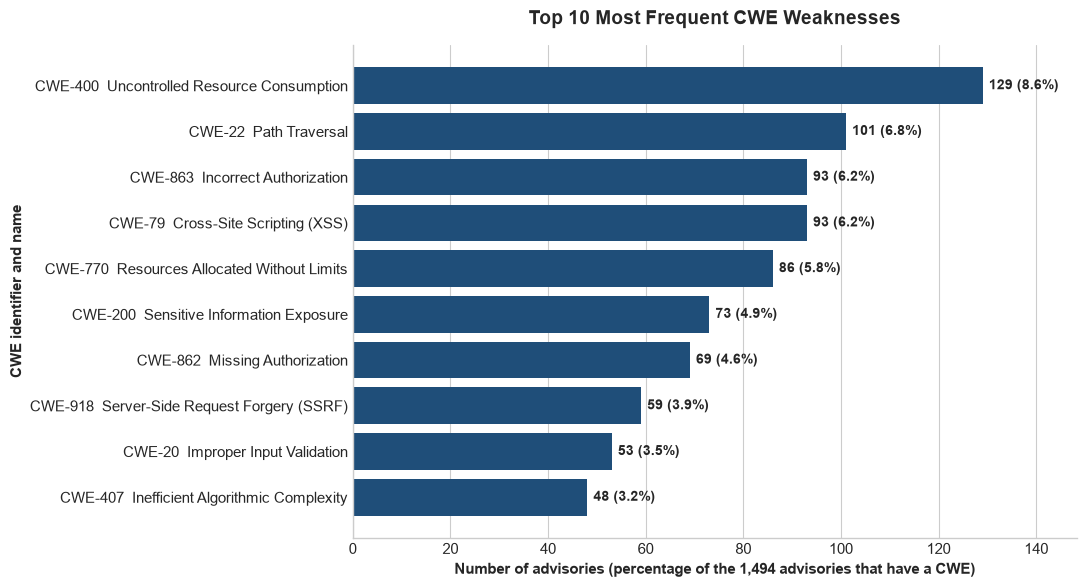

In [38]:
# Short names from the public MITRE CWE list (only used to make chart labels readable)
CWE_NAMES = {
    "CWE-20": "Improper Input Validation",
    "CWE-22": "Path Traversal",
    "CWE-78": "OS Command Injection",
    "CWE-79": "Cross-Site Scripting (XSS)",
    "CWE-94": "Code Injection",
    "CWE-200": "Sensitive Information Exposure",
    "CWE-400": "Uncontrolled Resource Consumption",
    "CWE-407": "Inefficient Algorithmic Complexity",
    "CWE-693": "Protection Mechanism Failure",
    "CWE-770": "Resources Allocated Without Limits",
    "CWE-862": "Missing Authorization",
    "CWE-863": "Incorrect Authorization",
    "CWE-918": "Server-Side Request Forgery (SSRF)",
    "CWE-1333": "Inefficient Regular Expression (ReDoS)",
}

cwe = explode_multi(df, "cwe_ids").rename(columns={"cwe_ids": "cwe"})   # one row per (advisory, CWE)
n_with_cwe = int(df["cwe_ids"].notna().sum())
cwe_counts = cwe["cwe"].value_counts()
top_cwes = cwe_counts.head(10)

print(f"Advisories with at least one CWE : {n_with_cwe:,} of {len(df):,}")
print(f"Distinct CWE identifiers         : {cwe_counts.size}")
print(f"Total CWE tags (after splitting) : {len(cwe):,}\n")

labels = [f"{c}  {CWE_NAMES.get(c, '')}".strip() for c in top_cwes.index]

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(labels, top_cwes.values, color=PRIMARY_COLOR)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, v in enumerate(top_cwes.values):
    ax.text(v + top_cwes.max() * 0.01, y, f"{v} ({v / n_with_cwe * 100:.1f}%)", va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0, top_cwes.max() * 1.15)
ax.set_title("Top 10 Most Frequent CWE Weaknesses", pad=15)
ax.set_xlabel(f"Number of advisories (percentage of the {n_with_cwe:,} advisories that have a CWE)")
ax.set_ylabel("CWE identifier and name")
plt.tight_layout()
save_figure(fig, "cwe_analysis.png")
plt.show()

In [39]:
# Which weaknesses are typical for the most severe advisories?
crit_cwe = cwe.loc[cwe["severity"] == "critical", "cwe"].value_counts().head(5)
crit_table = pd.DataFrame({
    "name": [CWE_NAMES.get(c, "") for c in crit_cwe.index],
    "critical_advisories": crit_cwe.values,
}, index=crit_cwe.index)
print("Top 5 CWEs among CRITICAL advisories:")
display(crit_table)

DOS_IDS = {"CWE-400", "CWE-770", "CWE-407", "CWE-1333"}       # resource exhaustion / denial of service group
dos_adv = cwe.loc[cwe["cwe"].isin(DOS_IDS), "ghsa_id"].nunique()
dos_df = cwe.loc[cwe["cwe"].isin(DOS_IDS)].drop_duplicates("ghsa_id")
dos_critical = int((dos_df["severity"] == "critical").sum())
dos_high_medium = dos_df["severity"].isin(["high", "medium"]).mean() * 100
inj_df = cwe.loc[cwe["cwe"].isin({"CWE-94", "CWE-78"})].drop_duplicates("ghsa_id")
inj_critical_share = (inj_df["severity"] == "critical").mean() * 100
n_multi_cwe = int(df["cwe_ids"].str.contains(",", na=False).sum())

show(
    "**Key observations**",
    f"- **{top_cwes.index[0]}** ({CWE_NAMES.get(top_cwes.index[0], '')}) is the most frequent weakness with **{top_cwes.iloc[0]}** advisories ({top_cwes.iloc[0] / n_with_cwe * 100:.1f}%), "
    f"followed by **{top_cwes.index[1]}** ({top_cwes.iloc[1]}) and **{top_cwes.index[2]}** ({top_cwes.iloc[2]}).",
    f"- **{n_multi_cwe}** advisories ({n_multi_cwe / len(df) * 100:.1f}%) list more than one CWE, which is why splitting matters.",
    f"- Resource-exhaustion weaknesses (CWE-400, 770, 407, 1333) appear in **{dos_adv}** distinct advisories ({dos_adv / n_with_cwe * 100:.1f}% of advisories with a CWE).",
    f"- Of the resource-exhaustion advisories, **{dos_high_medium:.1f}%** are high or medium and **{dos_critical}** are critical.",
    f"- Advisories with code or OS command injection (CWE-94 / CWE-78) are critical in **{inj_critical_share:.1f}%** of cases, compared with {sev_pct['critical']:.1f}% for all advisories.",
    f"- The most common CWEs among **critical** advisories are **{crit_cwe.index[0]}** ({CWE_NAMES.get(crit_cwe.index[0], '')}, {crit_cwe.iloc[0]}) and **{crit_cwe.index[1]}** ({CWE_NAMES.get(crit_cwe.index[1], '')}, {crit_cwe.iloc[1]}).",
    f"- The long tail is large: {cwe_counts.size} distinct CWEs occur, and the top 10 cover {top_cwes.sum() / len(cwe) * 100:.1f}% of all CWE tags.",
)

Top 5 CWEs among CRITICAL advisories:


,name,critical_advisories
cwe,,
CWE-94,Code Injection,14
CWE-78,OS Command Injection,10
CWE-863,Incorrect Authorization,9
CWE-693,Protection Mechanism Failure,9
CWE-862,Missing Authorization,8


**Key observations**
- **CWE-400** (Uncontrolled Resource Consumption) is the most frequent weakness with **129** advisories (8.6%), followed by **CWE-22** (101) and **CWE-863** (93).
- **554** advisories (36.9%) list more than one CWE, which is why splitting matters.
- Resource-exhaustion weaknesses (CWE-400, 770, 407, 1333) appear in **226** distinct advisories (15.1% of advisories with a CWE).
- Of the resource-exhaustion advisories, **98.2%** are high or medium and **0** are critical.
- Advisories with code or OS command injection (CWE-94 / CWE-78) are critical in **29.1%** of cases, compared with 8.5% for all advisories.
- The most common CWEs among **critical** advisories are **CWE-94** (Code Injection, 14) and **CWE-78** (OS Command Injection, 10).
- The long tail is large: 217 distinct CWEs occur, and the top 10 cover 37.4% of all CWE tags.

**Interpretation:** the most frequent weaknesses fall into three families: **resource exhaustion**
(CWE-400, 770, 407), **access-control errors** (CWE-863, 862) and classic **web/input weaknesses** (CWE-22 path
traversal, CWE-79 cross-site scripting, CWE-918 SSRF). The weaknesses that lead the *critical* advisories are
different: code and command injection, which can let an attacker run code. Injection advisories are critical far more often than
the average advisory, while resource-exhaustion advisories are almost all high or medium and none is critical (see the observations
above). In short, the most *common* weakness is not the most *severe* one.

**Limitations:**
- CWE labels are assigned by advisory authors and reviewers, and can be broad or inconsistent.
- Percentages do not add up to 100% because an advisory with several CWEs is counted under each one.
- The ranking is for a six-week window; it may change over a longer period.
- The CWE names in the chart labels come from the public MITRE list; they are not stored in the database.

## 9. Temporal Analysis

**Research question:** how are advisories distributed over time (by day and by weekday)?

**What is measured:** the number of advisories published per calendar day with a 7-day rolling average, the
total per weekday, and a monthly summary.

**Scope:** the dataset covers only about six weeks (18 Sep - 30 Oct 2026), so a month-by-month *trend* line would have
just two points, and September is incomplete. Daily and weekday views are used instead.

Saved: outputs/visualizations/temporal_trends.png


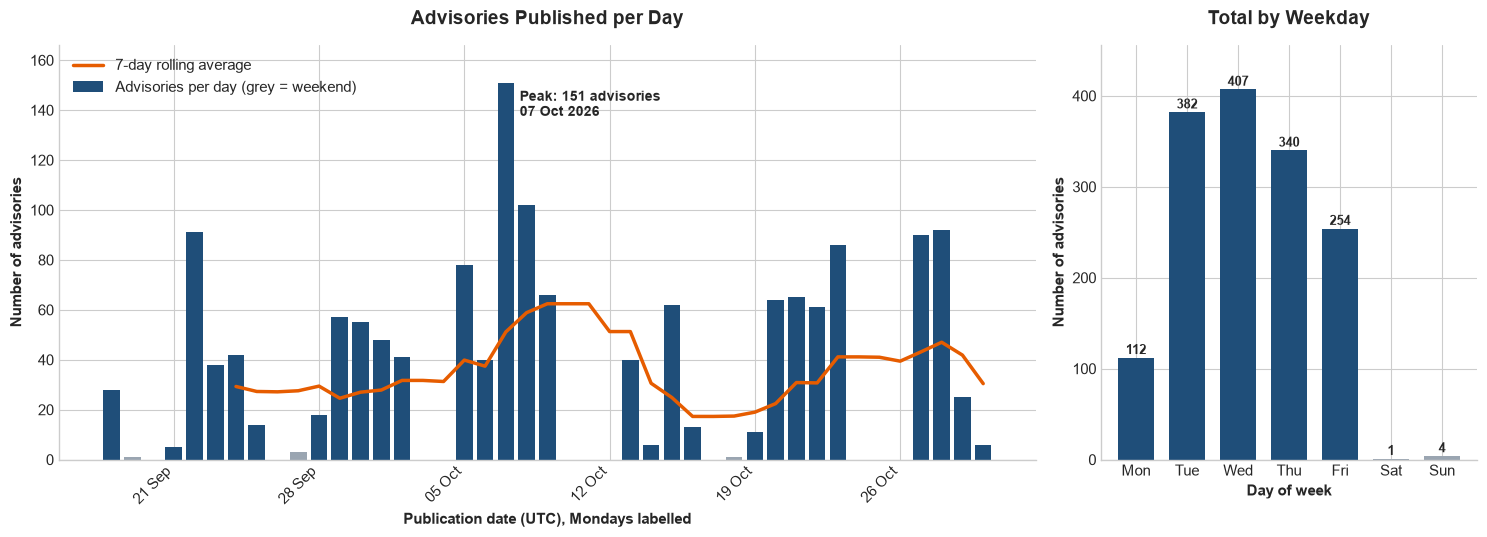

In [40]:
published_day = df["published_at"].dt.tz_convert("UTC").dt.tz_localize(None).dt.normalize()
all_days = pd.date_range(published_day.min(), published_day.max(), freq="D")
daily = published_day.value_counts().reindex(all_days, fill_value=0).sort_index()
rolling_7 = daily.rolling(window=7, min_periods=7).mean()          # trailing 7-day average

weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_totals = published_day.dt.day_of_week.value_counts().reindex(range(7), fill_value=0)

peak_day = daily.idxmax()
peak_rows = df.loc[published_day == peak_day]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2.6, 1]})

# Left: daily counts and rolling average
ax = axes[0]
bar_colors = ["#9aa5b1" if d.day_of_week >= 5 else PRIMARY_COLOR for d in daily.index]
ax.bar(daily.index, daily.values, color=bar_colors, width=0.8, label="Advisories per day (grey = weekend)")
ax.plot(rolling_7.index, rolling_7.values, color="#e65c00", linewidth=2.5, label="7-day rolling average")
ax.annotate(
    f"Peak: {daily.max()} advisories\n{peak_day:%d %b %Y}",
    xy=(peak_day, daily.max()), xytext=(10, -5), textcoords="offset points",
    fontsize=10, fontweight="bold", va="top",
)
ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_ylim(0, daily.max() * 1.1)
ax.set_title("Advisories Published per Day", pad=15)
ax.set_xlabel("Publication date (UTC), Mondays labelled")
ax.set_ylabel("Number of advisories")
ax.legend(frameon=False, loc="upper left")

# Right: total per weekday
ax = axes[1]
wk_colors = [PRIMARY_COLOR if i < 5 else "#9aa5b1" for i in range(7)]
ax.bar(weekday_names, weekday_totals.values, color=wk_colors, width=0.7)
for x, v in enumerate(weekday_totals.values):
    ax.text(x, v + weekday_totals.max() * 0.01, f"{v}", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, weekday_totals.max() * 1.12)
ax.set_title("Total by Weekday", pad=15)
ax.set_xlabel("Day of week")
ax.set_ylabel("Number of advisories")

plt.tight_layout()
save_figure(fig, "temporal_trends.png")
plt.show()

In [41]:
month = published_day.dt.to_period("M")
monthly = published_day.groupby(month).agg(first_day="min", last_day="max")
monthly["advisories"] = month.value_counts().sort_index()
monthly["calendar_days_covered"] = (monthly["last_day"] - monthly["first_day"]).dt.days + 1
monthly["advisories_per_calendar_day"] = (monthly["advisories"] / monthly["calendar_days_covered"]).round(1)
monthly["first_day"] = monthly["first_day"].dt.strftime("%d %b")
monthly["last_day"] = monthly["last_day"].dt.strftime("%d %b")
print("Monthly summary (September is only partly covered):")
display(monthly)

weekday_share = weekday_totals.iloc[:5].sum() / weekday_totals.sum() * 100
weekend_total = int(weekday_totals.iloc[5:].sum())
zero_days = daily[daily == 0]
zero_weekend = int((zero_days.index.day_of_week >= 5).sum())
busiest_weekday = weekday_names[int(weekday_totals.idxmax())]
peak_eco = peak_rows["ecosystem"].value_counts()
peak_pkg = peak_rows["package_name"].value_counts()

show(
    "**Key observations**",
    f"- Advisories were published on **{int((daily > 0).sum())} of {len(daily)}** calendar days; the average is **{daily.mean():.1f}** per day.",
    f"- **{weekday_share:.1f}%** were published Monday to Friday; only **{weekend_total}** appeared on a weekend. {busiest_weekday} is the busiest weekday.",
    f"- The peak day is **{peak_day:%d %b %Y}** with **{daily.max()}** advisories; on that day **{peak_eco.index[0]}** accounts for {peak_eco.iloc[0]} advisories "
    f"and the most frequent package is **{peak_pkg.index[0]}** ({peak_pkg.iloc[0]}).",
    f"- Of the {len(zero_days)} days without any advisory, {zero_weekend} were weekend days.",
)

Monthly summary (September is only partly covered):


,first_day,last_day,advisories,calendar_days_covered,advisories_per_calendar_day
published_at,,,,,
2026-09,18 Sep,30 Sep,352,13,27.1
2026-10,01 Oct,30 Oct,1148,30,38.3


**Key observations**
- Advisories were published on **32 of 43** calendar days; the average is **34.9** per day.
- **99.7%** were published Monday to Friday; only **5** appeared on a weekend. Wed is the busiest weekday.
- The peak day is **07 Oct 2026** with **151** advisories; on that day **npm** accounts for 93 advisories and the most frequent package is **ghost** (20).
- Of the 11 days without any advisory, 9 were weekend days.

**Interpretation:** publication follows the working week: almost nothing is published on Saturdays and Sundays, so
the daily series shows a regular weekly rhythm rather than random noise. The sharp peak on 7 October is not a steady
increase in vulnerabilities but a *burst* of publications: the observations above show that one ecosystem accounts for most of
that day, which is consistent with bulk publication by a few maintainers or projects. The data cannot show the exact cause.

**Limitations:**
- The data is the **latest 1,500 advisories**, not a random sample of history. The 43-day window is determined by the
  sample size, so the data cannot show long-term growth, seasonality or yearly trends.
- September covers only 13 days (18-30 Sep), so comparing the September and October *totals* would be
  misleading; the per-calendar-day column in the monthly table is the fair comparison.
- `published_at` is the date GitHub published the advisory, not the date the vulnerability was discovered or exploited.

## 10. Package Analysis

**Research question:** which individual packages are affected by the most advisories?

**What is measured:** the number of advisories per package name.

**Counting rule:** an advisory can affect several packages (`package_name` holds a comma-separated list), so the
column is split first. Each package is counted once per advisory, so there is no double counting.

Distinct packages: 696
Packages with exactly one advisory: 405
Packages with five or more advisories: 106

Saved: outputs/visualizations/package_analysis.png


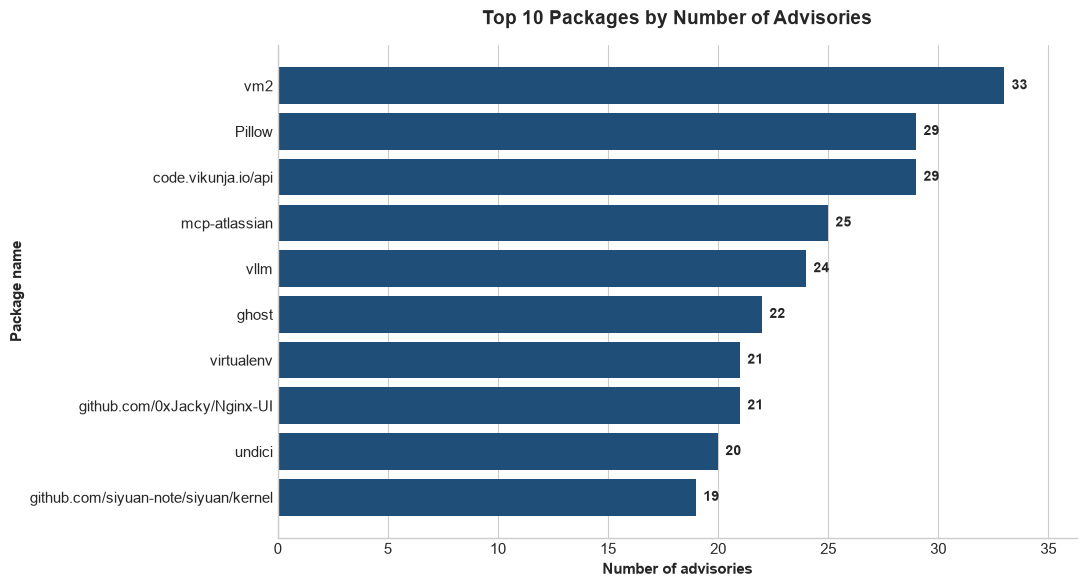

In [42]:
pkg = explode_multi(df, "package_name").rename(columns={"package_name": "package"})
pkg = pkg.drop_duplicates(subset=["ghsa_id", "package"])           # safety: one count per advisory and package
pkg_counts = pkg["package"].value_counts()
top_pkgs = pkg_counts.head(10)

n_unique_pkgs = pkg_counts.size
single_pkgs = int((pkg_counts == 1).sum())
repeat_pkgs = int((pkg_counts >= 5).sum())

print(f"Distinct packages: {n_unique_pkgs:,}")
print(f"Packages with exactly one advisory: {single_pkgs:,}")
print(f"Packages with five or more advisories: {repeat_pkgs}\n")

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top_pkgs.index, top_pkgs.values, color=PRIMARY_COLOR)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
for y, v in enumerate(top_pkgs.values):
    ax.text(v + top_pkgs.max() * 0.01, y, f"{v}", va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0, top_pkgs.max() * 1.1)
ax.set_title("Top 10 Packages by Number of Advisories", pad=15)
ax.set_xlabel("Number of advisories")
ax.set_ylabel("Package name")
plt.tight_layout()
save_figure(fig, "package_analysis.png")
plt.show()

In [43]:
top10_share = top_pkgs.sum() / len(pkg) * 100

show(
    "**Key observations**",
    f"- **{n_unique_pkgs:,}** distinct packages appear in the {len(df):,} advisories.",
    f"- **{top_pkgs.index[0]}** has the most advisories (**{top_pkgs.iloc[0]}**), followed by **{top_pkgs.index[1]}** ({top_pkgs.iloc[1]}) and **{top_pkgs.index[2]}** ({top_pkgs.iloc[2]}).",
    f"- **{single_pkgs / n_unique_pkgs * 100:.1f}%** of the packages ({single_pkgs:,}) have just one advisory.",
    f"- The ten most affected packages together account for only **{top10_share:.1f}%** of all package-advisory pairs, so the problem is spread over many packages.",
)

**Key observations**
- **696** distinct packages appear in the 1,500 advisories.
- **vm2** has the most advisories (**33**), followed by **Pillow** (29) and **code.vikunja.io/api** (29).
- **58.2%** of the packages (405) have just one advisory.
- The ten most affected packages together account for only **12.7%** of all package-advisory pairs, so the problem is spread over many packages.

**Interpretation:** advisories are **widely spread** across hundreds of packages: no single package dominates, and
most packages appear only once. A small group of packages is hit repeatedly: the package at the top of the chart received dozens of advisories
in six weeks, which may reflect a security review or a series of related disclosures. Counts alone cannot tell whether such a
package is poorly secured or simply scrutinised more.

**Limitations:**
- A package name is not guaranteed to be unique across ecosystems (the same name could exist in npm and pip).
- The counts say nothing about package popularity: one advisory in a package used by millions can matter more
  than ten advisories in an unused package.
- Counts cover only the six-week window of the dataset.

## 11. Key Findings

The findings below are generated directly from the data in the previous sections, so the numbers always match the
charts.

In [44]:
show(
    f"1. **Dataset:** {len(df):,} GitHub-reviewed advisories published between {df['published_at'].min():%d %b %Y} and {df['published_at'].max():%d %b %Y} "
    f"({len(daily)} days). The SQLite database and the processed CSV contain the same records.",
    f"2. **Data quality:** no duplicates; only {n_no_cvss} advisories ({n_no_cvss / len(df) * 100:.1f}%) lack a CVSS score; {n_withdrawn} advisories are withdrawn and flagged.",
    f"3. **Severity:** {top_sev} ({sev_pct[top_sev]:.1f}%) and medium ({sev_pct['medium']:.1f}%) dominate; critical is {sev_pct['critical']:.1f}% ({sev_counts['critical']} advisories).",
    f"4. **Ecosystems:** {top3[0]}, {top3[1]} and {top3[2]} cover {top3_adv / len(df) * 100:.1f}% of all advisories; the severity mix is similar in these three.",
    f"5. **CVSS:** mean {mean_cvss:.2f}, median {median_cvss:.2f} (n = {n_scored:,}). Severity levels map to separate score bands (no overlap: {bands_do_not_overlap}).",
    f"6. **CWE:** the most frequent weakness is {top_cwes.index[0]} ({CWE_NAMES.get(top_cwes.index[0], '')}, {top_cwes.iloc[0]} advisories); "
    f"critical advisories are led by {crit_cwe.index[0]} ({CWE_NAMES.get(crit_cwe.index[0], '')}) and {crit_cwe.index[1]} ({CWE_NAMES.get(crit_cwe.index[1], '')}).",
    f"7. **Time:** {weekday_share:.1f}% of advisories were published on weekdays; the busiest day was {peak_day:%d %b %Y} with {daily.max()} advisories.",
    f"8. **Packages:** {n_unique_pkgs:,} distinct packages are affected; {single_pkgs / n_unique_pkgs * 100:.1f}% have only one advisory, and the top ten make up only {top10_share:.1f}% of all package-advisory pairs.",
)

1. **Dataset:** 1,500 GitHub-reviewed advisories published between 18 Sep 2026 and 30 Oct 2026 (43 days). The SQLite database and the processed CSV contain the same records.
2. **Data quality:** no duplicates; only 14 advisories (0.9%) lack a CVSS score; 26 advisories are withdrawn and flagged.
3. **Severity:** high (42.9%) and medium (41.4%) dominate; critical is 8.5% (128 advisories).
4. **Ecosystems:** npm, pip and go cover 84.4% of all advisories; the severity mix is similar in these three.
5. **CVSS:** mean 6.83, median 7.10 (n = 1,486). Severity levels map to separate score bands (no overlap: True).
6. **CWE:** the most frequent weakness is CWE-400 (Uncontrolled Resource Consumption, 129 advisories); critical advisories are led by CWE-94 (Code Injection) and CWE-78 (OS Command Injection).
7. **Time:** 99.7% of advisories were published on weekdays; the busiest day was 07 Oct 2026 with 151 advisories.
8. **Packages:** 696 distinct packages are affected; 58.2% have only one advisory, and the top ten make up only 12.7% of all package-advisory pairs.

## 12. Conclusion

This project built a complete ETL and EDA workflow for open-source security advisories: extraction from the GitHub
API, cleaning with pandas, validation with Pydantic, storage in SQLite and an exploratory analysis in this notebook.

**What the analysis shows**
- Advisories are concentrated in the **high** and **medium** severity levels, and in three ecosystems: **npm, pip and Go**.
- The severity label and the CVSS score contain the same information: each severity level is a separate CVSS band.
- The most frequent weaknesses are resource exhaustion, access-control errors and classic web weaknesses, but the most
  severe advisories are led by **code and command injection**.
- Advisories are published almost only on **weekdays**, in bursts (such as the peak day), and are spread over hundreds of
  packages rather than concentrated in a few.

**Improvements made to the original project**
- Missing CVSS scores are stored as missing instead of 0.0, and CVSS v4 scores are now extracted, which raised the number of
  usable scores from 1,071 to 1,486.
- CWE, ecosystem and package values are split before counting, so multi-value advisories are counted correctly.
- Validation now runs before loading, and the database table keeps its explicit schema and primary key.

**Limitations to keep in mind**
- The dataset is the *latest 1,500 reviewed advisories* (about six weeks), so conclusions about long-term trends are not possible.
- Counts describe advisories, not exploitation, popularity or real-world damage.
- Ecosystem and package counts are not normalised by ecosystem size or package popularity.
- CVSS v3 and v4 scores are combined; withdrawn advisories (1.7%) are kept and flagged.

**Reproducibility:** from the project root run `python pipeline.py --skip-extract` to rebuild the processed CSV and the
database from the saved raw file, then open this notebook and choose *Restart Kernel and Run All Cells*. All charts are
regenerated in `outputs/visualizations/`.

In [45]:
print("Charts saved in outputs/visualizations/:")
for path in sorted(VIZ_DIR.glob("*.png")):
    print(f"  - {path.name}")

Charts saved in outputs/visualizations/:
  - cvss_by_severity.png
  - cvss_distribution.png
  - cwe_analysis.png
  - data_quality.png
  - ecosystem_analysis.png
  - ecosystem_severity.png
  - package_analysis.png
  - severity_distribution.png
  - temporal_trends.png
